## Path

In [1]:
# Pengaturan path (jalankan paling awal)
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/midnightbluee2/TBP-PCD.git"

if "google.colab" in sys.modules:              # Colab: clone repo ke /content
    BASE = Path("/content/TBP-PCD")
    if not BASE.exists():
        subprocess.run(["git", "clone", REPO_URL, str(BASE)], check=True)
else:                                          # Lokal: folder tempat notebook
    BASE = Path.cwd()

FOTO_DIR  = BASE / "data" / "foto"
HASIL_DIR = BASE / "hasil"
DCT_DIR   = HASIL_DIR / "dct"
STEGO_DIR = HASIL_DIR / "stego"

print("BASE     :", BASE)
print("FOTO_DIR :", FOTO_DIR, "| ada" if FOTO_DIR.is_dir() else "| TIDAK ADA")

BASE     : d:\PCD\TBP-PCD
FOTO_DIR : d:\PCD\TBP-PCD\data\foto | ada


## LSB Content-Adaptive

4 foto dimuat

No  Nama foto                 Label       Pesan   Ukuran
1   BACTERIA-1157929-0001     PNEUMONIA   RM001   (512, 512)
2   BACTERIA-4269599-0003     PNEUMONIA   RM002   (512, 512)
3   NORMAL-528189-0001        NORMAL      RM003   (512, 512)
4   NORMAL-1101909-0001       NORMAL      RM004   (512, 512)


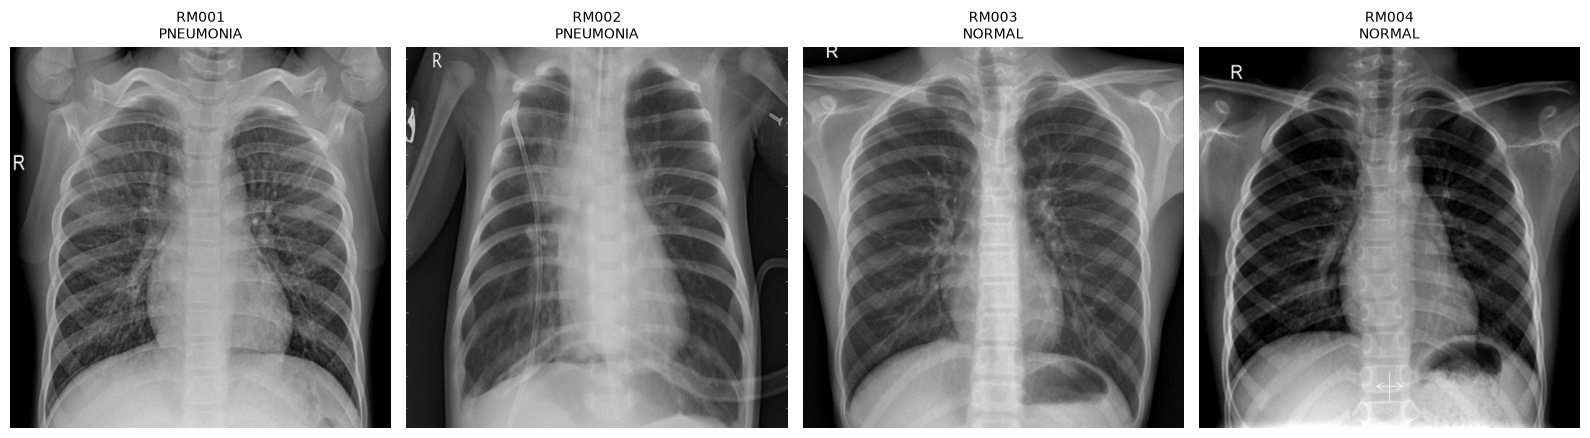

In [5]:
import os
import cv2
import matplotlib.pyplot as plt

# Pengaturan
FOLDER = str(FOTO_DIR)
URUTAN = ["BACTERIA-1157929-0001", "BACTERIA-4269599-0003",
          "NORMAL-528189-0001", "NORMAL-1101909-0001"]
PESAN  = ["RM001", "RM002", "RM003", "RM004"]
UKURAN = 512

EKSTENSI = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

def tebak_label(nama):
    t = nama.lower()
    if any(k in t for k in ("pneumonia", "bacteria", "virus")):
        return "PNEUMONIA"
    return "NORMAL" if "normal" in t else "TIDAK_DIKETAHUI"

def muat_foto(folder, urutan, pesan, ukuran=512):
    jalur = [os.path.join(a, f) for a, _, fs in os.walk(folder) for f in fs
             if f.lower().endswith(EKSTENSI)]
    if not jalur:
        raise FileNotFoundError(f"Tidak ada foto di folder: {folder}")
    peta = {os.path.splitext(os.path.basename(p))[0].lower(): p for p in jalur}
    hilang = [n for n in urutan if n.lower() not in peta]
    if hilang:
        raise FileNotFoundError(f"Foto tidak ditemukan: {hilang}. Foto yang ada: {sorted(peta)}")
    if len(pesan) != len(urutan):
        raise ValueError("Jumlah PESAN harus sama dengan jumlah foto")
    data = []
    for n, ps in zip(urutan, pesan):
        img = cv2.resize(cv2.imread(peta[n.lower()], 0), (ukuran, ukuran), interpolation=cv2.INTER_AREA)
        data.append({"nama": n, "label": tebak_label(n), "pesan": ps, "img": img})
    return data

def simpan(img, path, qf=None):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if qf:
        cv2.imwrite(path, img, [cv2.IMWRITE_JPEG_QUALITY, int(qf)])
    else:
        cv2.imwrite(path, img)


# Running & Output
data = muat_foto(FOLDER, URUTAN, PESAN, UKURAN)

print(f"{len(data)} foto dimuat\n")
print(f"{'No':<4}{'Nama foto':<26}{'Label':<12}{'Pesan':<8}{'Ukuran'}")
for i, d in enumerate(data, 1):
    print(f"{i:<4}{d['nama']:<26}{d['label']:<12}{d['pesan']:<8}{d['img'].shape}")

fig, ax = plt.subplots(1, len(data), figsize=(4 * len(data), 4.5))
for x, d in zip(ax, data):
    x.imshow(d["img"], cmap="gray")
    x.set_title(f"{d['pesan']}\n{d['label']}", fontsize=10)
    x.axis("off")
plt.tight_layout(); plt.show()

## DCT Basis-3

Foto                    Pesan   Digit basis-3  Blok dipakai  Koef berubah
BACTERIA-1157929-0001   RM001   56             14            37
BACTERIA-4269599-0003   RM002   56             14            40
NORMAL-528189-0001      RM003   56             14            38
NORMAL-1101909-0001     RM004   56             14            36

Selesai. 4 gambar stego disimpan di folder: d:\PCD\TBP-PCD\hasil\dct/ (format PNG)


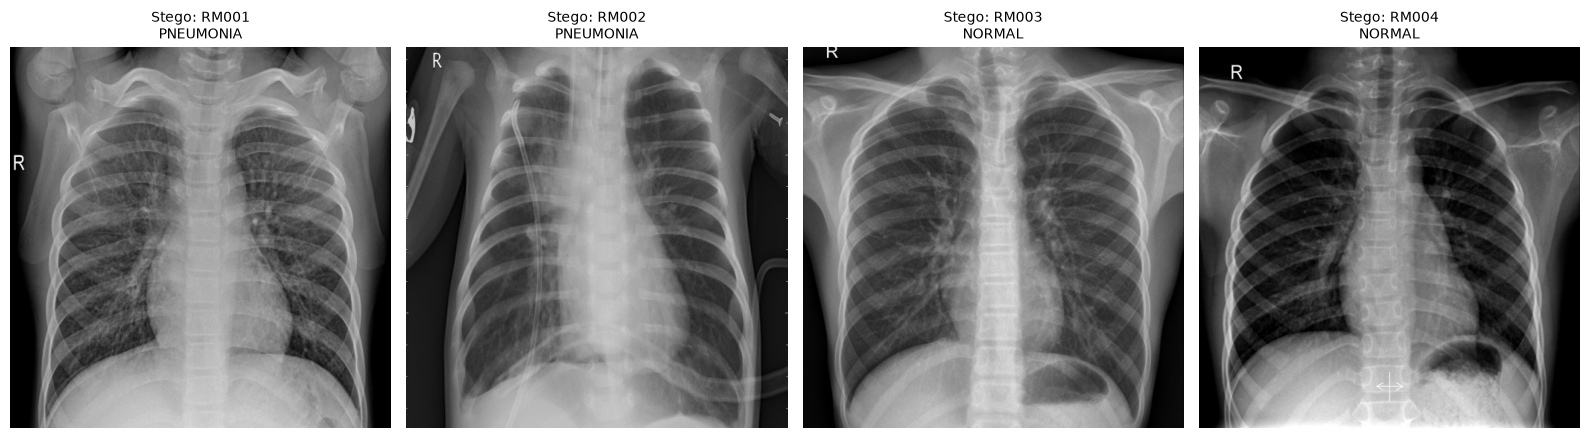

In [6]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

assert "data" in globals(), "Jalankan sel DATASET dulu supaya variabel `data` ada."

# Pengaturan
QF = 90                       # menentukan ukuran langkah pembulatan koefisien
FOLDER_HASIL = str(DCT_DIR)    # hasil disimpan sebagai PNG (tanpa kompresi lossy)

AKHIR = "#####"                # penanda akhir pesan
POSISI_ZIGZAG = [4, 5, 6, 7]   # 4 koefisien menengah per blok 8x8 (urutan zigzag)
QDASAR = np.array([
    [16, 11, 10, 16, 24, 40, 51, 61], [12, 12, 14, 19, 26, 58, 60, 55],
    [14, 13, 16, 24, 40, 57, 69, 56], [14, 17, 22, 29, 51, 87, 80, 62],
    [18, 22, 37, 56, 68, 109, 103, 77], [24, 35, 55, 64, 81, 104, 113, 92],
    [49, 64, 78, 87, 103, 121, 120, 101], [72, 92, 95, 98, 112, 100, 103, 99]], dtype=np.float32)

def tabel_kuantisasi(qf):
    skala = 5000 / qf if qf < 50 else 200 - 2 * qf
    return np.clip(np.floor((QDASAR * skala + 50) / 100), 1, 255).astype(np.float32)

def urutan_zigzag(n=8):
    p = [(r, c) for r in range(n) for c in range(n)]
    p.sort(key=lambda x: (x[0] + x[1], x[0] if (x[0] + x[1]) % 2 == 1 else x[1]))
    return p

def teks_ke_basis3(teks):
    """teks -> biner -> potongan 6 bit -> 4 digit basis 3 (0/1/2)"""
    bits = "".join(f"{b:08b}" for b in (teks + AKHIR).encode("utf-8"))
    bits += "0" * (-len(bits) % 6)
    digit = []
    for i in range(0, len(bits), 6):
        n, d = int(bits[i:i + 6], 2), []
        for _ in range(4):
            d.append(n % 3); n //= 3
        digit += d[::-1]
    return digit

def sesuaikan(c, s):
    """bilangan bulat terdekat dari c (rentang c-2..c+2) dengan c mod 3 = s"""
    for k in sorted(range(c - 2, c + 3), key=lambda k: abs(k - c)):
        if k % 3 == s:
            return k

def sisipkan_dct(img, teks, qf=90):
    h, w = img.shape
    digit = teks_ke_basis3(teks)
    if len(digit) > (h // 8) * (w // 8) * len(POSISI_ZIGZAG):
        raise ValueError("Pesan terlalu panjang untuk gambar ini")
    Q = tabel_kuantisasi(qf)
    zz = urutan_zigzag()
    posisi = [zz[i] for i in POSISI_ZIGZAG]
    out, k, blok, berubah = img.copy(), 0, 0, 0
    for r in range(0, h, 8):
        for c in range(0, w, 8):
            if k >= len(digit):
                return out, len(digit), blok, berubah
            q = np.round(cv2.dct(out[r:r+8, c:c+8].astype(np.float32) - 128) / Q).astype(np.int32)
            for (i, j) in posisi:
                lama = int(q[i, j])
                q[i, j] = sesuaikan(lama, digit[k])
                berubah += int(q[i, j] != lama)
                k += 1
            rec = cv2.idct(q.astype(np.float32) * Q) + 128
            out[r:r+8, c:c+8] = np.clip(np.round(rec), 0, 255).astype(np.uint8)
            blok += 1
    return out, len(digit), blok, berubah


# Penyisipan
os.makedirs(FOLDER_HASIL, exist_ok=True)
hasil_dct = []

print(f"{'Foto':<24}{'Pesan':<8}{'Digit basis-3':<15}{'Blok dipakai':<14}{'Koef berubah'}")
for d in data:
    stego, n_digit, blok, berubah = sisipkan_dct(d["img"], d["pesan"], QF)
    cv2.imwrite(f"{FOLDER_HASIL}/{d['nama']}_stego.png", stego)
    hasil_dct.append({"nama": d["nama"], "pesan": d["pesan"], "label": d["label"], "stego": stego})
    print(f"{d['nama'][:23]:<24}{d['pesan']:<8}{n_digit:<15}{blok:<14}{berubah}")

print(f"\nSelesai. {len(hasil_dct)} gambar stego disimpan di folder: {FOLDER_HASIL}/ (format PNG)")

fig, ax = plt.subplots(1, len(hasil_dct), figsize=(4 * len(hasil_dct), 4.5))
for x, h_ in zip(ax, hasil_dct):
    x.imshow(h_["stego"], cmap="gray")
    x.set_title(f"Stego: {h_['pesan']}\n{h_['label']}", fontsize=10)
    x.axis("off")
plt.tight_layout(); plt.show()

## LSB

BACTERIA-1157929-0001 [PNEUNOMIA] | secret_message: RM001 | extracted: RM001 
BACTERIA-4269599-0003 [PNEUNOMIA] | secret_message: RM002 | extracted: RM002 
NORMAL-528189-0001 [NORMAL] | secret_message: RM003 | extracted: RM003 
NORMAL-1101909-0001 [NORMAL] | secret_message: RM004 | extracted: RM004 


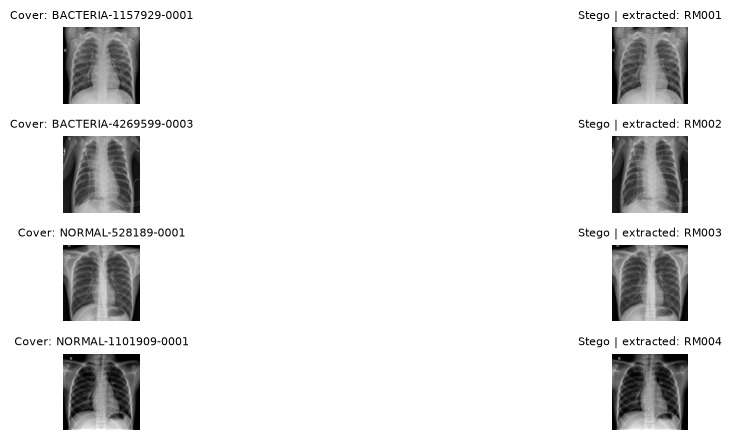

In [7]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# env
DATASET = str(FOTO_DIR)
OUTPUT_DIR = str(STEGO_DIR)
SEQUENCE = [
    "BACTERIA-1157929-0001", "BACTERIA-4269599-0003",
    "NORMAL-528189-0001", "NORMAL-1101909-0001"
]
SECRET_MESSAGE = ["RM001", "RM002", "RM003", "RM004"]
IMG_SCALE = 512
IMG_EXT = (".jpg", ".jpeg", ".png")
BLOCK = 8
COEF_A, COEF_B = (4, 3), (3, 4)
STRENGTH = 30.0
HEADER_BITS = 16


def guess_label(name):
    t = name.lower()
    if any(k in t for k in ("pneunomia", "bacteria", "virus")):
        return "PNEUNOMIA"
    return "NORMAL" if "normal" in t else "UNKNOWN"


def load_img(dataset, seq, msg, size=IMG_SCALE):
    paths = [os.path.join(a, f) for a, _, fs in os.walk(dataset) for f in fs
             if f.lower().endswith(IMG_EXT)]
    if not paths:
        raise FileNotFoundError(f"image is not found in dataset: {dataset}")
    mapping = {os.path.splitext(os.path.basename(p))[0].lower(): p for p in paths}
    missing = [n for n in seq if n.lower() not in mapping]
    if missing:
        raise FileNotFoundError(f"image is not found: {missing}. existing image: {sorted(mapping)}")
    if len(msg) != len(seq):
        raise ValueError("number of msg should same with number of img")
    data = []
    for n, m in zip(seq, msg):
        img = cv2.resize(cv2.imread(mapping[n.lower()], 0), (size, size), interpolation=cv2.INTER_AREA)
        data.append({"name": n, "label": guess_label(n), "msg": m, "img": img})
    return data


# --- flow 1: embedding ---
def text_to_binary(text):
    payload = "".join(f"{b:08b}" for b in text.encode("utf-8"))
    return f"{len(payload):0{HEADER_BITS}b}" + payload


def binary_to_text(bits):
    chars = [int(bits[i:i + 8], 2) for i in range(0, len(bits), 8)]
    return bytes(chars).decode("utf-8", errors="replace")


def block_positions(shape):
    h, w = shape
    return [(r, c) for r in range(0, h - h % BLOCK, BLOCK)
            for c in range(0, w - w % BLOCK, BLOCK)]


def embed_binary(cover, bits):
    positions = block_positions(cover.shape)
    if len(bits) > len(positions):
        raise ValueError(f"message too long: {len(bits)} bits > {len(positions)} blocks")
    stego = cover.astype(np.float32).copy()
    for (r, c), bit in zip(positions, bits):
        block = cv2.dct(stego[r:r + BLOCK, c:c + BLOCK])
        a, b = block[COEF_A], block[COEF_B]
        mean = (a + b) / 2
        if bit == "1" and a - b < STRENGTH:
            block[COEF_A], block[COEF_B] = mean + STRENGTH / 2, mean - STRENGTH / 2
        elif bit == "0" and b - a < STRENGTH:
            block[COEF_A], block[COEF_B] = mean - STRENGTH / 2, mean + STRENGTH / 2
        stego[r:r + BLOCK, c:c + BLOCK] = cv2.idct(block)
    return np.clip(np.round(stego), 0, 255).astype(np.uint8)


def save_stego(stego, name, out_dir=OUTPUT_DIR):
    os.makedirs(out_dir, exist_ok=True)
    path = os.path.join(out_dir, f"{name}_stego.png")
    cv2.imwrite(path, stego)
    return path


# --- flow 2: extraction ---
def extract_binary(stego):
    positions = block_positions(stego.shape)
    img = stego.astype(np.float32)
    bits = []
    for r, c in positions:
        block = cv2.dct(img[r:r + BLOCK, c:c + BLOCK])
        bits.append("1" if block[COEF_A] > block[COEF_B] else "0")
        if len(bits) == HEADER_BITS:
            total = HEADER_BITS + int("".join(bits), 2)
        if len(bits) == HEADER_BITS + 1 and total > len(positions):
            raise ValueError("invalid header: image has no valid hidden message")
        if len(bits) >= HEADER_BITS and len(bits) == total:
            break
    return "".join(bits[HEADER_BITS:])


# --- run ---
data = load_img(DATASET, SEQUENCE, SECRET_MESSAGE)

fig, axes = plt.subplots(len(data), 2, figsize=(4 * len(data), 4.5))
for i, d in enumerate(data):
    bits = text_to_binary(d["msg"])
    stego = embed_binary(d["img"], bits)
    path = save_stego(stego, d["name"])

    stego_loaded = cv2.imread(path, 0)
    extracted = binary_to_text(extract_binary(stego_loaded))
    print(f"{d['name']} [{d['label']}] | secret_message: {d['msg']} | extracted: {extracted} ")

    axes[i, 0].imshow(d["img"], cmap="gray")
    axes[i, 0].set_title(f"Cover: {d['name']}", fontsize=8)
    axes[i, 1].imshow(stego_loaded, cmap="gray")
    axes[i, 1].set_title(f"Stego | extracted: {extracted}", fontsize=8)
    for ax in axes[i]:
        ax.axis("off")
plt.tight_layout()
plt.show()